This follows the path laid out in 'FullFit_ordered1.ipynb' and starts off from the progress and framework made in reflectivity_fitting_v3.ipynb

---
### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling


------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


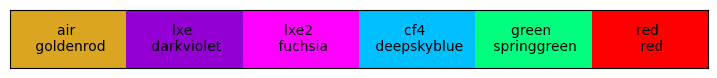

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import scipy.integrate as spi

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
# %run "PDE_fittingFunction.py"

In [72]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, cutinWl/wlen, 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
        
    return PDE

def PDE_allArgs_triple(wlen, theta1, FF, tOxide, dp_star, Xp, Xn, dw_star, pe, ph, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    # pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    # Wp, Wn = pn.calcW_both(photon)
    Wp = ME.Abs_layers(d_above=dp_star, d_region=Xp-dp_star, mu=photon.muSi, theta=photon.theta_3)
    
    WfxPf = ME.Abs_Pslope_convolution(dx_p=Xp, dx_n=Xn, mu=photon.muSi, Pstart=pe, Pend=ph, theta=photon.theta_3)
    
    Wn = ME.Abs_layers(d_above=Xn, d_region=dw_star-Xn, mu=photon.muSi, theta=photon.theta_3)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, cutinWl/wlen, 1)
        pe = 1-(1-pe)**nyield
        
    PDE = FF * Ttotal * (Wp*pe + WfxPf + Wn*ph)
        
    return PDE

def PDE_allArgs_tripleTrue(wlen, theta1, FF, tOxide, dp_star, Xp, Xn, dw_star, pe, pf, ph, quantum = False):
    photon = PhotonInfo(wlen, theta1)
    Ttotal = photon.T_total_windowAndOxide(tOxide)
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    # pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    # Wp, Wn = pn.calcW_both(photon)
    Wp = ME.Abs_layers(d_above=dp_star, d_region=Xp-dp_star, mu=photon.muSi, theta=photon.theta_3)
    
    Wf = ME.Abs_layers(d_above=Xp, d_region=Xn-Xp, mu=photon.muSi, theta=photon.theta_3)
    
    Wn = ME.Abs_layers(d_above=Xn, d_region=dw_star-Xn, mu=photon.muSi, theta=photon.theta_3)
    
    if quantum:
        # nyield = (380/wlen)
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, cutinWl/wlen, 1)
        pe = 1-(1-pe)**nyield
        
    PDE = FF * Ttotal * (Wp*pe + Wf*pf + Wn*ph)
        
    return PDE

In [4]:
def parab(scale, x):
    return scale * x**2

def doIntegral(x):
    return spi.quad(parab, 0, x)[0]

# someRanges = np.linspace(0, 4, 2)
# doIntegral(someRanges)

# doIntegral(1)

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
absval =  0.4999625740850562
absval2 =  [0.48881461 0.5       ]


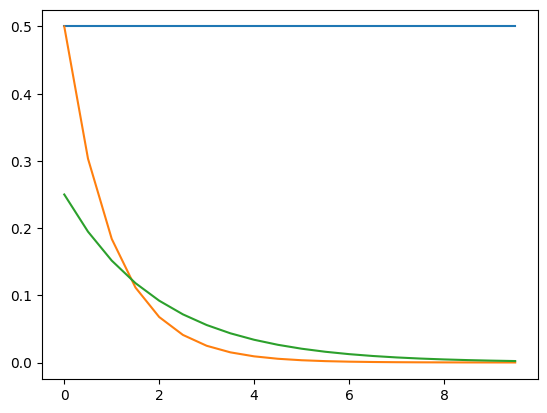

In [5]:
xtest = np.linspace(0, 10, 20, endpoint=0)
width = max(xtest) - min(xtest)

photon = PhotonInfo(500, 0)

Pstart = 0.5
Pend = 0.5

yPslope = ME.Pgradient(xtest, width, Pstart, Pend)
yPabs = ME.differential_absorption(xtest, 1, width, Pstart, Pend)

yPabs2 = ME.differential_absorption(xtest, 0.5, width, Pstart, Pend)

absValue = ME.Abs_Pslope_convolution(dx_p=0, dx_n=max(xtest), mu=1, Pstart=Pstart, Pend=Pend)
print("absval = ", absValue)

absValue2 = ME.Abs_Pslope_convolution(dx_p=0, dx_n=max(xtest), mu=np.array([0.4, 10]), Pstart=Pstart, Pend=Pend)
print("absval2 = ", absValue2)

plt.plot(xtest, yPslope)
plt.plot(xtest, yPabs)
plt.plot(xtest, yPabs2)

# # plt.plot(xtest, yDiffAbs)
# plt.plot(xtest, 0.1*np.exp(-xtest*0.1))

---
### Loading Data

In [86]:
file_path = os.path.join(PROPATH, "../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv")
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())

# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)



      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


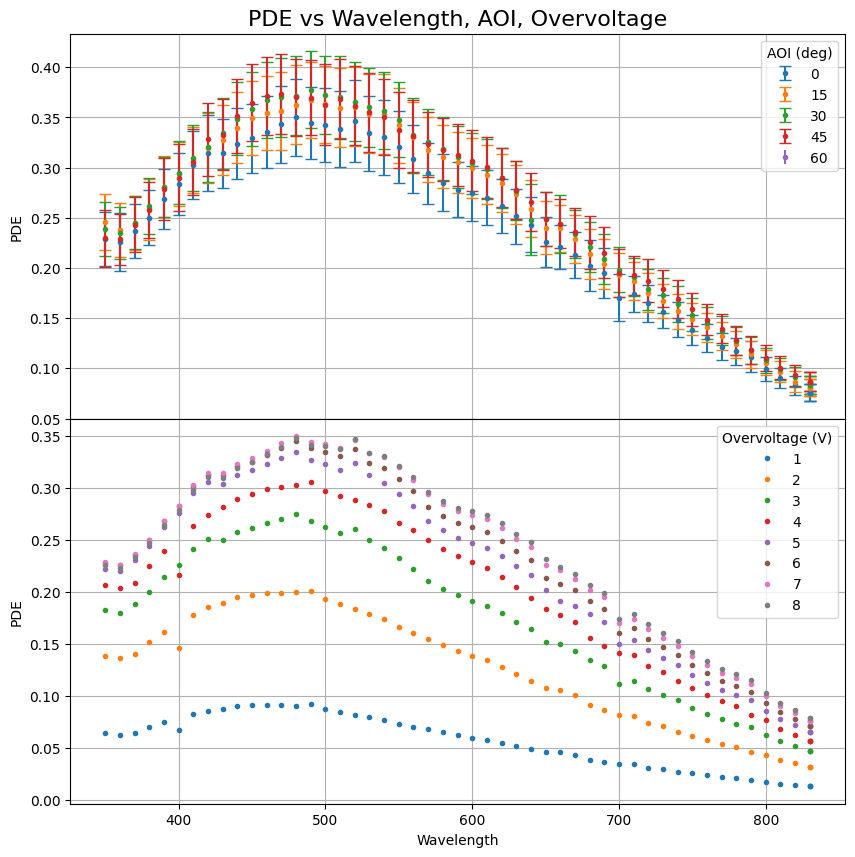

Angles: [0 1 2 3 4 5 6 7 8]
voltages: [0 1 2 3 4 5 6 7 8]


In [83]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 7)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

    Wavelength  Overvoltage  Raw rate     Error  normalized rate
45         380            1   85685.2  4284.260         0.486306
46         380            2  129270.0   102.441         0.733673
47         380            3  151277.0   112.130         0.858569
48         380            4  163067.0   117.333         0.925484
49         380            5  169473.0   120.277         0.961845
50         380            6  172971.0   121.836         0.981696
51         380            7  174974.0   122.416         0.993065
52         380            8  175686.0   122.464         0.997103
53         380            9  176196.0  8809.810         1.000000
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


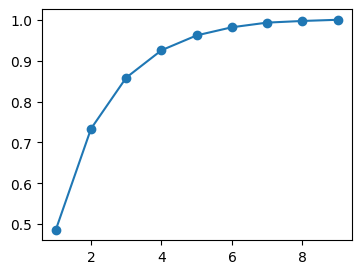

In [52]:
## Loading in Harry's PE data
file_path_pe = os.path.join(PROPATH, "../veraData/HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 3))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

In [87]:
angle_0A = data_angles[0]
voltageTracker = []
for V in data_voltages[1:]:
    voltageTracker.append(V) 
voltageTracker = voltageTracker[:-1]
df = df[(df['Wavelength'] != 399.975)]

---
---
### Trying triple fit - linear connection

0.19999999999999996


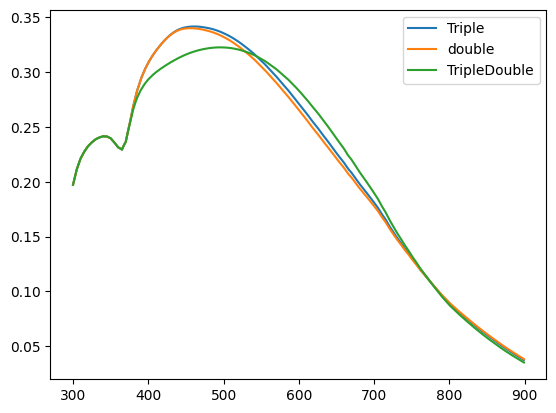

In [108]:
## plotting PDE if probabilities were 1 (for Wp, Wn)

xVals = np.arange(300, 900, 1)
finBoring = {'tOxide': 16.5, 'theta1': 0, 'FF': 0.6, 'quantum': False}

finPN_triple = {'dp_star': 1.5, 'Xp': 1.8e3, 'Xn': 2e3, 'dw_star': 10e3}
finP_triple = {'pe': 1.0, 'ph': 0.2}

finPN_tripleDouble = {'dp_star': 1.5, 'Xp': 0.08e3, 'Xn': 3e3, 'dw_star': 8e3}
finP_tripleDouble = {'pe': 1.0, 'pf':0.9, 'ph': 0.1}

finPN_double = {'dp_star': 1.5, 'Xpn': 1.8e3, 'dw_star': 11e3}
finP_double = {'pe': 1.0, 'ph': 0.2}

twidth = finPN_triple["Xn"] - finPN_triple["Xp"]
print(ME.Pgradient(twidth, dwidth=twidth, Pstart=1, Pend=0.2))

yPDE_triple = PDE_allArgs_triple(xVals, **finBoring, **finPN_triple, **finP_triple)

yPDE_tripleDouble = PDE_allArgs_tripleTrue(xVals, **finBoring, **finPN_tripleDouble, **finP_tripleDouble)

yPDE = PDE_allArgs(xVals, **finBoring, **finPN_double, **finP_double)

plt.plot(xVals, yPDE_triple, label='Triple')
plt.plot(xVals, yPDE, label='double')
plt.plot(xVals, yPDE_tripleDouble, label='TripleDouble')
# plt.plot(xVals, yPDE_P + yPDE_N, label='Wp + Wn')

plt.legend()
plt.show()

---
---
### Might as well try! linear connection - DOESN'T WORK 

* fixed global: $dp^*$
* float global: $X_{p}$, $X_{n}$, $dw^*$

* fixed nested: $P_e$
* nested float: $P_h$

In [89]:
# values from global1 fit (best fit)
peDict_fitGlobal_previous = {1: (0.2553, 0.0034), 2: (0.5659, 0.0099), 3: (0.7659, 0.01), 4: (0.8708, 0.0106), 5: (0.9444, 0.0114), 6: (0.9763, 0.0133), 7: (0.992, 0.0156), 8: (0.9831, 0.0169)}
phDict_fitGlobal = {1: (0.015, 0.0022), 2: (0.0552, 0.0069), 3: (0.101, 0.0072), 4: (0.1433, 0.0082), 5: (0.1745, 0.0088), 6: (0.2057, 0.0106), 7: (0.2378, 0.0127), 8: (0.2633, 0.0147)}

In [90]:
scaleErrors = 0.3
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
print(voltageTracker)

data_global1 = []
visCut = 900
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < visCut)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    fixedNested = {}
    
    fullFloat = {"ph": 0.15, "pe": peDict_fitGlobal_previous[V][0]}
    fullBounds = {"ph": (0.0, 1.1), "pe": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat,
                                          nuisanceBounds=fullBounds, nuisanceFixed=fixedNested)
    odFull_global.extraV = V
    data_global1.append(odFull_global)
# global fixed

[1 2 3 4 5 6 7 8]
[1, 2, 3, 4, 5, 6, 7]


In [93]:
# print("List of args needed:", SS.GetNames(PDE_allArgs))

# fixedPars_global1 = {"dp_star":1.5, 'tOxide': 16.5,'FF': 0.6, 'quantum': False}
# print("\nfixed inputs:", fixedPars_global1)

# floatPars_global1 = {"Xp": 1.2e3, "Xn": 3e3, "dw_star": 12e3}
# floatParBounds_global1 = {"Xp": (0.8e3, 8e3), "Xn": (1e3, 8e3), "dw_star": (2e3, 20e3)}

# x0_global1, x0_global1_Names = SS.BuildX0(floatDict=floatPars_global1, functionToFit=PDE_allArgs_triple)
# x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=PDE_allArgs_triple)

# print("------ Case global1 setup ------")

# SS.GenericResiduals_Nuisance_1(globalFloat=x0_global1, globalFixed=fixedPars_global1, dataPackage=data_global1,
#                                functionToFit=PDE_allArgs_triple, verbose=False)


In [94]:
# globalFit_global1 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global1, bounds = x0_global1_bounds,
#                                         args=(fixedPars_global1, data_global1, PDE_allArgs_triple), method='migrad')
# SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global1.x, globalFixed=fixedPars_global1, dataPackage=data_global1,
#                                     functionToFit=PDE_allArgs_triple, verbose=False)
# print("Done fit!")


In [95]:
# # print(globalFit_Visall_S)
# print("score:", globalFit_global1.fun)
# resDict_global1 = SS.GetResDict(globalFit_global1, x0_global1_Names)
# resDictError_global1 = SS.GetResErrorDict(globalFit_global1, x0_global1_Names)
# print(resDict_global1)
# print(resDictError_global1)

# phFull_dict_global1 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global1}
# peFull_dict_global1 = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global1}

# print("ph:", phFull_dict_global1)

In [96]:
# dict_final_global1 = {**resDict_global1, **fixedPars_global1}
# print(dict_final_global1)
# for dc in data_global1:
#     oneD = dc.oneDData[0]
#     xwlen = oneD["wlen"]
#     y = oneD["yVals"]
#     yErrs = oneD["yErrs"]
    
#     voltage = dc.extraV
#     localPh = phFull_dict_global1[voltage][0]
    
#     col = ms.GetNextColor()
    
#     yFit = PDE_allArgs_triple(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global1, **dc.resultDict, **dc.mDict_nuisFixed)
#     plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
#     plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
# plt.legend()
# plt.show()

In [97]:
# yph = [phFull_dict_global1[voltage][0] for voltage in voltageTracker]
# yphErr = [phFull_dict_global1[voltage][1] for voltage in voltageTracker]

# ype = [peFull_dict_global1[voltage][0] for voltage in voltageTracker]
# ypeErr = [peFull_dict_global1[voltage][1] for voltage in voltageTracker]
# plt.errorbar(voltageTracker, ype, ypeErr, label="pe")

# yPeHarry = [harryPedict[V] for V in voltageTracker]

# plt.errorbar(voltageTracker, yph, yphErr, label="ph")
# plt.plot(voltageTracker, yPeHarry, label="pe Harry")
# plt.legend()
# plt.show()

---
---
### Trying - floating middle P value

In [100]:
scaleErrors = 0.3
##-- Buiding Vis all dataset --##
print(data_voltages[1:])
print(voltageTracker)

data_global2 = []
visCut = 900
for V in voltageTracker:
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < visCut)]
    oneD_dict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": dfA_t1['PDE_error']*scaleErrors, "theta1": angle_0A}
    
    fixedNested = {"pe": peDict_fitGlobal_previous[V][0]}
    
    fullFloat = {"pf":0.8, "ph": 0.15}
    fullBounds = {"pf": (0.0, 1.1), "ph": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat,
                                          nuisanceBounds=fullBounds, nuisanceFixed=fixedNested)
    odFull_global.extraV = V
    data_global2.append(odFull_global)


[1 2 3 4 5 6 7 8]
[1, 2, 3, 4, 5, 6, 7]


In [109]:
# global fixed
print("List of args needed:", SS.GetNames(PDE_allArgs_tripleTrue))

fixedPars_global2 = {"dp_star":1.5, "dw_star": 11.5e3, 'tOxide': 16.5,'FF': 0.6, 'quantum': False}
print("\nfixed inputs:", fixedPars_global2)

floatPars_global2 = {"Xp": 0.15e3, "Xn": 4e3}
floatParBounds_global2 = {"Xp": (0.1e3, 8e3), "Xn": (1e3, 10e3)}

x0_global2, x0_global2_Names = SS.BuildX0(floatDict=floatPars_global2, functionToFit=PDE_allArgs_tripleTrue)
x0_global2_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global2, functionToFit=PDE_allArgs_tripleTrue)

print("------ Case global2 setup ------")

SS.GenericResiduals_Nuisance_1(globalFloat=x0_global2, globalFixed=fixedPars_global2, dataPackage=data_global2,
                               functionToFit=PDE_allArgs_tripleTrue, verbose=False)


List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xp', 'Xn', 'dw_star', 'pe', 'pf', 'ph', 'quantum']

fixed inputs: {'dp_star': 1.5, 'dw_star': 11500.0, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False}
------ Case global2 setup ------


4166.959707194514

In [110]:

globalFit_global2 = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global2, bounds = x0_global2_bounds,
                                        args=(fixedPars_global2, data_global2, PDE_allArgs_tripleTrue), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global2.x, globalFixed=fixedPars_global2, dataPackage=data_global2,
                                    functionToFit=PDE_allArgs_tripleTrue, verbose=False)
print("Done fit!")

ERROR: Nuisance fit did not converge


ValueError: Nuisance fit did not converge

score: 412.2490392984915
{'Xp': 1843.0932, 'Xn': 7999.9995}
{'Xp': 10.9076, 'Xn': 0.7618}
ph: {1: (0.0569, 0.0021), 2: (0.1522, 0.0179), 3: (0.1994, 0.0189), 4: (0.1502, 0.021), 5: (0.2302, 0.023), 6: (0.198, 0.0278), 7: (0.1537, 0.0336)}
{'Xp': 1843.0932, 'Xn': 7999.9995, 'dp_star': 1.5, 'dw_star': 11500.0, 'tOxide': 16.5, 'FF': 0.6, 'quantum': False}


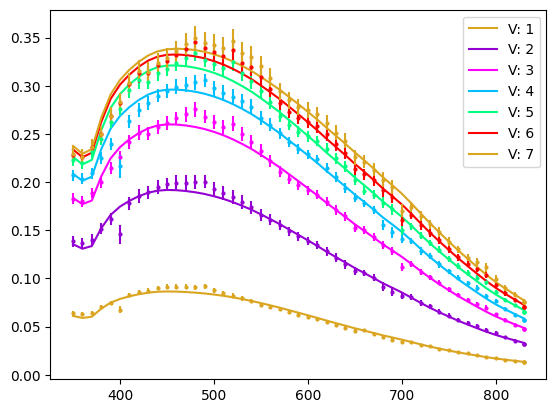

In [ ]:
# print(globalFit_Visall_S)
print("score:", globalFit_global2.fun)
resDict_global2 = SS.GetResDict(globalFit_global2, x0_global2_Names)
resDictError_global2 = SS.GetResErrorDict(globalFit_global2, x0_global2_Names)
print(resDict_global2)
print(resDictError_global2)

phFull_dict_global2 = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global2}
pfFull_dict_global2 = {dc.extraV: (dc.resultDict["pf"], dc.resultErrorsDict["pf"]) for dc in data_global2}

print("ph:", phFull_dict_global2)
dict_final_global2 = {**resDict_global2, **fixedPars_global2}
print(dict_final_global2)
for dc in data_global2:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localPh = phFull_dict_global2[voltage][0]
    
    col = ms.GetNextColor()
    
    yFit = PDE_allArgs_tripleTrue(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global2, **dc.resultDict, **dc.mDict_nuisFixed)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
plt.legend()
plt.show()

In [ ]:
yph = [phFull_dict_global2[voltage][0] for voltage in voltageTracker]
yphErr = [phFull_dict_global2[voltage][1] for voltage in voltageTracker]

ype = [peFull_dict_global2[voltage][0] for voltage in voltageTracker]
ypeErr = [peFull_dict_global2[voltage][1] for voltage in voltageTracker]
plt.errorbar(voltageTracker, ype, ypeErr, label="pe")

yPeHarry = [harryPedict[V] for V in voltageTracker]

plt.errorbar(voltageTracker, yph, yphErr, label="ph")
plt.plot(voltageTracker, yPeHarry, label="pe Harry")
plt.legend()
plt.show()